# Coordinate frames, transform chains and marker-based localisation

A pose estimate is only useful once it is expressed in the frame where the robot needs it. The
camera says "the tag is 0.9 m in front of *me*"; the arm planner needs "the object is at
$(0.83, -0.05, 0.07)$ in *base_link*". Getting there means composing transforms correctly,
including the infamous OpenCV-vs-ROS camera axis convention.

In this notebook we build a small synthetic **robot work cell** (a table with four AprilTags as a
map, a box with a tag on top, a robot with a head camera) where every frame is known exactly, and:

1. practise the $T_{ab}$ notation, composition and inversion, and rotation representations
   (matrix, axis-angle, quaternion, roll-pitch-yaw),
2. convert between the **OpenCV optical frame** and the **ROS REP-103** body frame,
3. compute an object's pose and a **grasp pose in the robot base frame** from one camera image,
4. **localise a moving camera** from the tag map: single-tag IPPE versus one joint PnP over all
   visible tags (and see the planar ambiguity break the single-tag estimate),
5. compare a **ChArUco board** with a single marker of the same size.

**What you'll learn:** frame bookkeeping that does not go wrong, REP-103/REP-105 conventions, why
more (spread-out) points beat one square, and how to verify transforms numerically.

**Prerequisites:** notebook 02 of this project (marker detection and PnP).

## Setup

Same camera model as notebook 02 (TUM fr1 intrinsics, ideal pinhole, 640x480). Notebook 02 found the
AprilTag 3 library's corners the most accurate, so tags are detected with `pupil_apriltags` when it
is installed (falling back to OpenCV with sub-pixel refinement otherwise).

In [1]:
# --- Setup: imports, device summary, paths, camera, detector ---
import io
import os
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.spatial.transform import Rotation

from cvlab import device as cvdevice
from cvlab import geometry as G
from cvlab import io as cvio
from cvlab import tum, viz
from cvlab.metrics import ate

# CPU-only notebook: hide the GPU before cvlab.device imports torch, so this kernel never
# creates a CUDA context and can run next to GPU jobs.
os.environ["CUDA_VISIBLE_DEVICES"] = ""
device = cvdevice.setup(seed=0)
viz.set_style()

PROJECT = "07_pose_estimation"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))
import fiducial_sim as fs
import table_scene as ts

SEQ = cvio.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk")
CAM, _ = tum.camera_for(SEQ.name)
K, W, H = CAM.K, CAM.width, CAM.height
RGB_FILES = sorted((SEQ / "rgb").glob("*.png"))
TABLE_PHOTO = cv2.imread(str(RGB_FILES[300]))  # table-top texture (BGR)
BG = np.full((H, W, 3), 60, np.uint8)  # dark grey "floor" around the table
D36 = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_APRILTAG_36h11)
try:
    import pupil_apriltags

    PUPIL = pupil_apriltags.Detector(families="tag36h11", nthreads=1, quad_decimate=1.0)
except ImportError:
    PUPIL = None
ARUCO = fs.make_detector(D36, "subpix")

def detect_tags(img):
    # {tag id: 4x2 corners (OpenCV order and pixel convention)} from the best available detector.
    if PUPIL is not None:
        return {i: r["corners"] for i, r in fs.pupil_detect(PUPIL, img, K, 1.0).items()}
    return fs.detect(ARUCO, img)

def show_jpeg(fig, quality=88):
    # Photo-heavy figures are displayed as JPEG to keep the committed notebook small.
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=100, pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))

rng = np.random.default_rng(0)
print(f"camera {W}x{H}, fx={K[0, 0]} | tag detector: {'pupil_apriltags' if PUPIL else 'cv2.aruco subpix'}")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cpu | GPU: none
camera 640x480, fx=517.3 | tag detector: pupil_apriltags


## 1. Notation: $T_{ab}$ maps points from frame $b$ into frame $a$

We write a rigid transform as a $4\times4$ matrix
$T_{ab} = \begin{bmatrix} R_{ab} & t_{ab} \\ 0 & 1\end{bmatrix}$ with $p_a = T_{ab}\,p_b$. Read it as "pose of
frame $b$ expressed in frame $a$": the columns of $R_{ab}$ are $b$'s axes written in $a$, and
$t_{ab}$ is $b$'s origin in $a$. Then

$$
T_{ac} = T_{ab}\,T_{bc} \quad(\text{inner indices cancel}),\qquad
T_{ba} = T_{ab}^{-1} = \begin{bmatrix} R_{ab}^\top & -R_{ab}^\top t_{ab} \\ 0 & 1\end{bmatrix}.
$$

If the indices of a product do not chain ($T_{ab}T_{cd}$), the expression is wrong. `solvePnP`
returns $T_{\text{cam},\text{marker}}$; ROS `tf2` stores the same thing as a transform with
`header.frame_id = cam`, `child_frame_id = marker`.

Rotations have several representations; all of them describe the same $R$:

| representation | used by | notes |
|---|---|---|
| $3\times3$ matrix | maths, `cvlab.geometry` | 9 numbers, orthonormal, $\det = +1$ |
| axis-angle $\omega = \theta\,\hat k$ | OpenCV `rvec`, `cv2.Rodrigues` | 3 numbers, singular at $\theta = \pi$ |
| quaternion $(x, y, z, w)$ | ROS messages, SciPy, `cvlab` | 4 numbers, $q$ and $-q$ are the same rotation |
| roll-pitch-yaw | ROS URDF `rpy`, `static_transform_publisher` | fixed-axis $X$ then $Y$ then $Z$: $R = R_z(y)R_y(p)R_x(r)$; gimbal lock at pitch $\pm 90°$ |

In [2]:
# --- One rotation, four representations, round-tripped through OpenCV, SciPy and cvlab ---
R = ts.Rz(30) @ ts.Ry(-20) @ ts.Rx(10)                    # yaw 30, pitch -20, roll 10 [deg]
rvec = cv2.Rodrigues(R)[0].ravel()                        # OpenCV axis-angle [rad]
q_xyzw = G.R_to_quat(R)                                   # cvlab: (x, y, z, w), w >= 0
rpy = Rotation.from_matrix(R).as_euler("xyz", degrees=True)  # extrinsic X-Y-Z = ROS roll, pitch, yaw
checks = {
    "rvec -> R": np.abs(cv2.Rodrigues(rvec)[0] - R).max(),
    "cvlab quat -> R": np.abs(G.quat_to_R(q_xyzw) - R).max(),
    "scipy quat == cvlab quat": np.abs(Rotation.from_matrix(R).as_quat(canonical=True) - q_xyzw).max(),
    "rpy -> R": np.abs(Rotation.from_euler("xyz", rpy, degrees=True).as_matrix() - R).max(),
    "so3_log == rvec": np.abs(G.so3_log(R) - rvec).max(),
}
print("rvec [rad]:", rvec.round(4), "| angle", np.degrees(np.linalg.norm(rvec)).round(3), "deg")
print("quaternion (x, y, z, w):", q_xyzw.round(4))
print("roll, pitch, yaw [deg]:", rpy.round(3))
pd.Series(checks, name="max abs difference")

rvec [rad]: [ 0.2603 -0.2953  0.5474] | angle 38.63 deg
quaternion (x, y, z, w): [ 0.1277 -0.1449  0.2685  0.9437]
roll, pitch, yaw [deg]: [ 10. -20.  30.]


rvec -> R                   2.220446e-16
cvlab quat -> R             2.220446e-16
scipy quat == cvlab quat    5.551115e-17
rpy -> R                    2.220446e-16
so3_log == rvec             1.110223e-16
Name: max abs difference, dtype: float64

## 2. OpenCV optical frame vs ROS REP-103

* **OpenCV / optical frame:** $x$ right, $y$ down, $z$ forward along the optical axis. All of
  OpenCV (projection, `solvePnP`, `drawFrameAxes`) uses it. ROS calls it `*_optical_frame`.
* **ROS body frame (REP-103):** $x$ forward, $y$ left, $z$ up. Used for `base_link`,
  `camera_link`, `map`, `odom` (REP-105).

The fixed rotation between them is `cvlab.geometry.R_ROS_FROM_OPENCV`
($p_\text{link} = R\,p_\text{optical}$): the optical $z$ (forward) becomes the body $x$, optical $x$
(right) becomes body $-y$, optical $y$ (down) becomes body $-z$. In a URDF or with
`static_transform_publisher` this is the `camera_link -> camera_optical_frame` transform with
roll-pitch-yaw $(-90°, 0, -90°)$, i.e. quaternion $(-0.5, 0.5, -0.5, 0.5)$.

In [3]:
# --- Verify the optical -> body rotation and its ROS parameterisations ---
R_lo = G.R_ROS_FROM_OPENCV                              # camera_link <- camera_optical
print("R_link_optical =\n", R_lo)
print("optical z (forward) in link frame:", R_lo @ [0, 0, 1], "| optical x (right):", R_lo @ [1, 0, 0],
      "| optical y (down):", R_lo @ [0, 1, 0])
print("quaternion (x, y, z, w):", G.R_to_quat(R_lo))
print("roll, pitch, yaw [deg]:", Rotation.from_matrix(R_lo).as_euler("xyz", degrees=True))
print("det =", np.linalg.det(R_lo), "(proper rotation, no handedness flip)")

R_link_optical =
 [[ 0.  0.  1.]
 [-1.  0.  0.]
 [ 0. -1.  0.]]
optical z (forward) in link frame: [1. 0. 0.] | optical x (right): [ 0. -1.  0.] | optical y (down): [ 0.  0. -1.]
quaternion (x, y, z, w): [-0.5  0.5 -0.5  0.5]
roll, pitch, yaw [deg]: [-90.   0. -90.]
det = 1.0 (proper rotation, no handedness flip)


## 3. The work cell and its frame tree

The scene (defined in `scripts/table_scene.py`) has the frame tree

```
world ──┬── tag0 … tag3            (map tags on the table, known poses)
        ├── object ── obj_tag      (box on the table, tag on its 7 cm high top face)
        └── base_link ── camera_link ── camera_optical
```

`world` is the table centre ($z$ up), `base_link` sits 0.8 m behind it, the head camera is 0.75 m
above the base and pitched down 40 deg. The table top is textured with a TUM desk photo. Every
transform below is ground truth; the camera only sees pixels.

In [4]:
# --- Build the scene and list every static transform as (xyz, roll-pitch-yaw) ---
scene = ts.make_scene(TABLE_PHOTO)
def describe(T):
    # Translation [m] and ROS roll/pitch/yaw [deg] of a 4x4 transform.
    return {"x": T[0, 3], "y": T[1, 3], "z": T[2, 3],
            **dict(zip(["roll", "pitch", "yaw"], Rotation.from_matrix(T[:3, :3]).as_euler("xyz", degrees=True)))}

tf_tree = {("world", f"tag{i}"): T for i, T in scene.T_world_tag.items()}
tf_tree |= {("world", "object"): scene.T_world_object, ("object", "obj_tag"): scene.T_object_objtag,
            ("world", "base_link"): scene.T_world_base, ("base_link", "camera_link"): scene.T_base_camlink,
            ("camera_link", "camera_optical"): scene.T_camlink_optical}
pd.DataFrame({f"{a} -> {b}": describe(T) for (a, b), T in tf_tree.items()}).T.round(3)

,x,y,z,roll,pitch,yaw
world -> tag0,0.45,0.30,0.00,0.0,0.0,0.0
world -> tag1,0.45,-0.30,0.00,0.0,0.0,90.0
world -> tag2,-0.45,-0.30,0.00,0.0,0.0,180.0
world -> tag3,-0.45,0.30,0.00,0.0,0.0,-90.0
world -> object,0.05,-0.05,0.00,0.0,0.0,30.0
object -> obj_tag,0.00,0.00,0.07,0.0,0.0,0.0
world -> base_link,-0.80,0.00,0.00,0.0,0.0,0.0
base_link -> camera_link,0.05,0.00,0.75,0.0,40.0,0.0
camera_link -> camera_optical,0.00,0.00,0.00,-90.0,0.0,-90.0


Render the head camera's view ($T_{\text{optical},\text{world}} = T_{\text{world},\text{optical}}^{-1}$
is what projects world points into the image) and draw the frame tree in 3D.

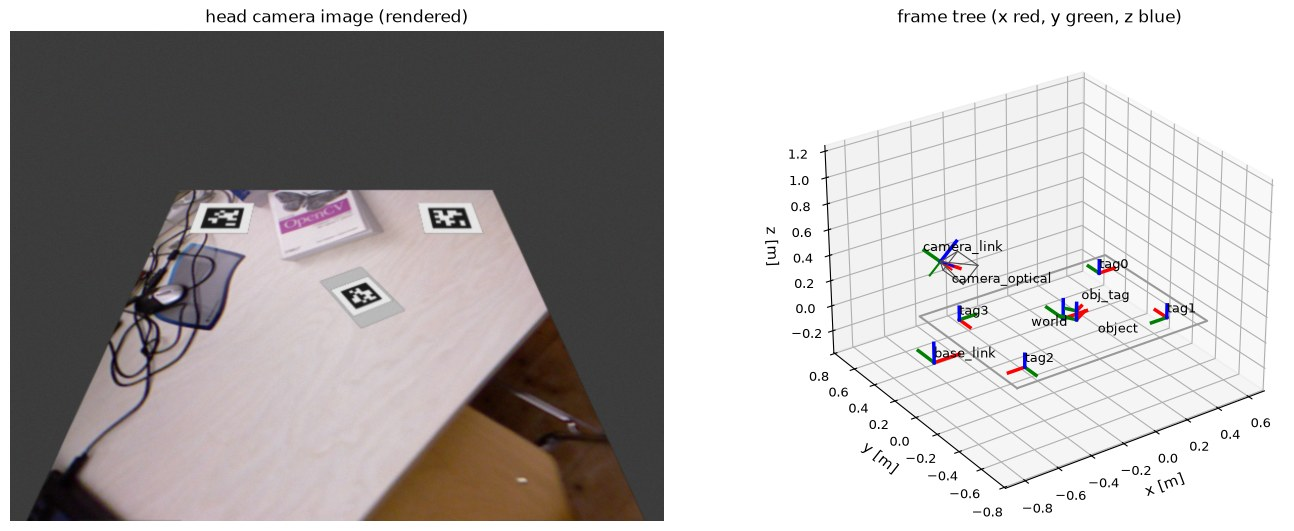

In [5]:
# --- Render the head-camera image and plot all frames in 3D ---
T_world_opt = scene.T_world_optical
head_img = fs.render_scene(scene.items, K, G.invert_T(T_world_opt), BG, rng=rng)

def draw_frame(ax, T, name, length=0.1, lw=2.5, offset=(0.0, 0.0, 0.04)):
    # Draw a frame's x/y/z axes (red/green/blue) at its origin and label it (offset in metres).
    o = T[:3, 3]
    for k, c in enumerate(["red", "green", "blue"]):
        e = o + length * T[:3, k]
        ax.plot(*np.stack([o, e]).T, color=c, lw=lw)
    ax.text(*(o + np.asarray(offset)), name, fontsize=9)

fig = plt.figure(figsize=(14, 5.2))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(head_img[..., ::-1])
ax1.set_title("head camera image (rendered)")
ax1.axis("off")
ax = fig.add_subplot(1, 2, 2, projection="3d")
tw, th = scene.items[0][0].size
ax.plot([-tw / 2, tw / 2, tw / 2, -tw / 2, -tw / 2], [-th / 2, -th / 2, th / 2, th / 2, -th / 2], 0, color="0.6")
draw_frame(ax, np.eye(4), "world", 0.15, offset=(-0.12, 0.12, -0.08))
for i, T in scene.T_world_tag.items():
    draw_frame(ax, T, f"tag{i}")
draw_frame(ax, scene.T_world_object, "object", offset=(0.05, -0.12, -0.05))
draw_frame(ax, scene.T_world_objtag, "obj_tag", 0.06, offset=(0.03, 0.0, 0.08))
draw_frame(ax, scene.T_world_base, "base_link", 0.15)
T_world_link = scene.T_world_base @ scene.T_base_camlink
draw_frame(ax, T_world_link, "camera_link", 0.15, offset=(-0.1, 0.0, 0.12))
draw_frame(ax, T_world_opt, "camera_optical", 0.1, lw=1.5, offset=(0.0, -0.1, -0.1))
viz.plot_camera_frustums(ax, T_world_opt[None], K, W, H, scale=0.15, color_rgb=(0.3, 0.3, 0.3))
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
ax.view_init(elev=28, azim=-125)
viz.set_axes_equal(ax)
ax.set_title("frame tree (x red, y green, z blue)")
viz.savefig(fig, PROJECT, "frames_scene")
show_jpeg(fig)

## 4. Object pose and grasp pose in the robot base frame

The camera detects `obj_tag` and PnP gives $T_{\text{optical},\text{obj\_tag}}$. The robot knows its
camera mounting from its URDF ($T_{\text{base},\text{link}}$, $T_{\text{link},\text{optical}}$), and the
object model says where the tag sits on the box ($T_{\text{object},\text{obj\_tag}}$). Chaining:

$$
T_{\text{base},\text{object}} = T_{\text{base},\text{link}}\;T_{\text{link},\text{optical}}\;
T_{\text{optical},\text{obj\_tag}}\;T_{\text{object},\text{obj\_tag}}^{-1}.
$$

Note the inverse at the end: we know the tag *in the object frame*, but need the object *in the
tag frame*. The wireframe box drawn from the estimate should sit on the rendered top face.

In [6]:
# --- Detect obj_tag in the head image and compute the object pose in base_link ---
dets = detect_tags(head_img)
res = fs.solve_marker_pose(dets[ts.OBJ_TAG_ID], ts.OBJ_TAG_SIZE, K)
T_opt_objtag = G.make_T(res.R, res.t)
T_base_object_est = scene.T_base_camlink @ scene.T_camlink_optical @ T_opt_objtag @ G.invert_T(scene.T_object_objtag)
T_base_object_gt = G.invert_T(scene.T_world_base) @ scene.T_world_object
obj_err = {"position_err_mm": 1000 * np.linalg.norm(T_base_object_est[:3, 3] - T_base_object_gt[:3, 3]),
           "rotation_err_deg": fs.rotation_error_deg(T_base_object_gt[:3, :3], T_base_object_est[:3, :3]),
           "distance_cam_to_tag_m": np.linalg.norm(res.t)}
head_vis = head_img.copy()
T_opt_object_est = G.invert_T(scene.T_base_camlink @ scene.T_camlink_optical) @ T_base_object_est
ts.draw_box(head_vis, K, T_opt_object_est)
for i, c in dets.items():
    r = fs.solve_marker_pose(c, scene.tag_size[i], K)
    cv2.drawFrameAxes(head_vis, K, None, cv2.Rodrigues(r.R)[0], r.t, 0.5 * scene.tag_size[i], 2)
print("detected tags:", sorted(dets))
print("T_base_object (estimate):\n", T_base_object_est.round(4))
pd.Series(obj_err).round(3)

detected tags: [0, 1, 10]
T_base_object (estimate):
 [[ 8.668e-01 -4.987e-01 -9.000e-04  8.465e-01]
 [ 4.987e-01  8.668e-01 -1.400e-03 -4.970e-02]
 [ 1.500e-03  7.000e-04  1.000e+00  3.000e-03]
 [ 0.000e+00  0.000e+00  0.000e+00  1.000e+00]]


position_err_mm          4.636
rotation_err_deg         0.129
distance_cam_to_tag_m    1.046
dtype: float64

**Grasp pose.** For a top-down parallel-jaw grasp we place the tool centre point (TCP) at the box's
centre, with the gripper's $z$ (approach) axis pointing **down** and its $x$ axis along the box's
long side: $T_{\text{object},\text{grasp}} = \big[R_x(180°)\;|\;(0, 0, h/2)\big]$. A **pre-grasp** pose
10 cm back along the approach axis is $T_{\text{object},\text{pre}} = T_{\text{object},\text{grasp}}\,
\text{Trans}(0, 0, -0.10)$ (right-multiplication moves along the *gripper's own* axes). A planner
such as MoveIt receives these as `geometry_msgs/PoseStamped` in `base_link`: position plus
quaternion $(x, y, z, w)$.

In [7]:
# --- Grasp and pre-grasp poses in base_link, formatted like a ROS PoseStamped ---
T_object_grasp = G.make_T(ts.Rx(180), [0.0, 0.0, ts.BOX_SIZE[2] / 2])
T_object_pre = T_object_grasp @ G.make_T(np.eye(3), [0.0, 0.0, -0.10])
grasp_rows = {}
for name, T_obj_x in [("grasp", T_object_grasp), ("pre_grasp", T_object_pre)]:
    T_est = T_base_object_est @ T_obj_x
    T_gt = T_base_object_gt @ T_obj_x
    q = G.R_to_quat(T_est[:3, :3])
    grasp_rows[name] = {"x": T_est[0, 3], "y": T_est[1, 3], "z": T_est[2, 3], "qx": q[0], "qy": q[1], "qz": q[2], "qw": q[3],
                        "err_mm": 1000 * np.linalg.norm(T_est[:3, 3] - T_gt[:3, 3])}
grasp_df = pd.DataFrame(grasp_rows).T
p = grasp_df.loc["pre_grasp"]
print("Equivalent ROS 2 static transform (documentation only - ROS is not part of this environment):")
print(f"ros2 run tf2_ros static_transform_publisher --x {p.x:.4f} --y {p.y:.4f} --z {p.z:.4f} "
      f"--qx {p.qx:.4f} --qy {p.qy:.4f} --qz {p.qz:.4f} --qw {p.qw:.4f} --frame-id base_link --child-frame-id pre_grasp")
grasp_df.round(4)

Equivalent ROS 2 static transform (documentation only - ROS is not part of this environment):
ros2 run tf2_ros static_transform_publisher --x 0.8464 --y -0.0499 --z 0.1380 --qx -0.9661 --qy -0.2581 --qz -0.0006 --qw 0.0005 --frame-id base_link --child-frame-id pre_grasp


,x,y,z,qx,qy,qz,qw,err_mm
grasp,0.8465,-0.0497,0.038,-0.9661,-0.2581,-0.0006,0.0005,4.6582
pre_grasp,0.8464,-0.0499,0.138,-0.9661,-0.2581,-0.0006,0.0005,4.7239


## 5. Localising a moving camera from a tag map

Now the camera moves (60 frames on an arc around the table, like a hand-held or arm-mounted camera).
The map tags' world poses $T_{\text{world},\text{tag}_i}$ are known, so each frame's camera pose follows from
the detections. Two strategies:

* **single tag:** take the largest visible map tag and invert its PnP pose,
  $T_{\text{world},\text{cam}} = T_{\text{world},\text{tag}_i}\,T_{\text{cam},\text{tag}_i}^{-1}$;
* **joint PnP:** express the corners of *all* visible map tags in world coordinates and solve one
  PnP (SQPnP + Levenberg-Marquardt refinement) for $T_{\text{cam},\text{world}}$. The points span the whole
  table instead of 10 cm, so the problem is far better conditioned and the planar ambiguity disappears.

Because the map is metric and absolute, no trajectory alignment is needed: ATE is computed
directly in the world frame (`align="none"`).

In [8]:
# --- Render the orbit, detect tags, localise each frame with both strategies ---
traj_gt = ts.orbit_trajectory(60)
est = {"single tag": [], "joint PnP": []}
n_visible, gif_frames = [], []
for k, T_wc in enumerate(traj_gt):
    img = fs.render_scene(scene.items, K, G.invert_T(T_wc), BG, rng=rng)
    d = detect_tags(img)
    n_visible.append(sum(i in scene.T_world_tag for i in d))
    est["single tag"].append(ts.localize_single(scene, d, K))
    est["joint PnP"].append(ts.localize_joint(scene, d, K))
    if k % 2 == 0:  # GIF frame: estimated world frame + object box drawn from the joint estimate
        T_cw = G.invert_T(est["joint PnP"][-1])
        vis = img.copy()
        cv2.drawFrameAxes(vis, K, None, cv2.Rodrigues(T_cw[:3, :3])[0], T_cw[:3, 3], 0.15, 2)
        ts.draw_box(vis, K, T_cw @ scene.T_world_object)
        gif_frames.append(vis[..., ::-1])
loc_rows, per_frame = [], {}
for name, poses in est.items():
    ok = np.array([p is not None for p in poses])
    E = np.stack([p for p in poses if p is not None])
    Gt = traj_gt[ok]
    pos_err = 1000 * np.linalg.norm(E[:, :3, 3] - Gt[:, :3, 3], axis=1)
    rot_err = np.array([fs.rotation_error_deg(a[:3, :3], b[:3, :3]) for a, b in zip(Gt, E)])
    per_frame[name] = (np.flatnonzero(ok), pos_err, rot_err, E)
    loc_rows.append({"method": name, "frames": f"{ok.sum()}/{len(ok)}", "ATE_rmse_mm": 1000 * ate(E[:, :3, 3], Gt[:, :3, 3], align="none")["rmse"],
                     "pos_err_median_mm": np.median(pos_err), "pos_err_max_mm": pos_err.max(),
                     "rot_err_median_deg": np.median(rot_err), "rot_err_max_deg": rot_err.max(),
                     "frames_>5deg": int((rot_err > 5).sum())})
gif_path = viz.save_gif(gif_frames, cvio.assets_dir(PROJECT) / "marker_localization.gif", fps=6, max_side=400)
print(f"visible map tags per frame: min {min(n_visible)}, max {max(n_visible)} | GIF: {gif_path.relative_to(ROOT)} "
      f"({gif_path.stat().st_size / 1e3:.0f} kB)")
loc_df = pd.DataFrame(loc_rows).set_index("method")
loc_df.round(3)

visible map tags per frame: min 3, max 4 | GIF: assets/07_pose_estimation/marker_localization.gif (759 kB)


,frames,ATE_rmse_mm,pos_err_median_mm,pos_err_max_mm,rot_err_median_deg,rot_err_max_deg,frames_>5deg
method,,,,,,,
single tag,60/60,140.900,2.180,1071.484,0.134,70.213,3
joint PnP,60/60,1.342,0.228,6.260,0.012,0.306,0


The worst single-tag frames are the planar ambiguity from notebook 02 in action: the largest tag
is seen at a moderate angle and the wrong IPPE branch wins, which rotates the whole camera pose
(and, through the lever arm of the tag-to-camera distance, moves it by a large amount).

In [9]:
# --- Inspect the worst single-tag frame ---
idx, pos_err, rot_err, E = per_frame["single tag"]
w = int(np.argmax(rot_err))
print(f"frame {idx[w]}: single-tag rotation error {rot_err[w]:.1f} deg, position error {pos_err[w]:.0f} mm; "
      f"joint PnP on the same frame: {per_frame['joint PnP'][2][w]:.2f} deg, {per_frame['joint PnP'][1][w]:.1f} mm")

frame 49: single-tag rotation error 70.2 deg, position error 1071 mm; joint PnP on the same frame: 0.08 deg, 2.1 mm


## 6. ChArUco board versus a single marker

A **ChArUco** board interleaves a chessboard with ArUco markers. The markers identify each square,
so a partially visible board still works, and the pose is computed from the *chessboard corners*:
saddle points that are localised symmetrically (no inward/outward bias) and to a small fraction of a
pixel. With dozens of points spread over the board there is no planar ambiguity in practice. The
same boards are used for camera calibration (`cv2.calibrateCamera` on `board.matchImagePoints`
output; project 01).

Board conventions differ from single markers: origin at the **top-left board corner**, $X$ right,
$Y$ **down**, $Z$ **into** the board. Pipeline in OpenCV 5:
`CharucoDetector.detectBoard` -> `board.matchImagePoints` -> `solvePnP` (`estimatePoseCharucoBoard`
is gone).

Is a board therefore more accurate than one big tag? We test it: a common 5x7 calibration board
with 3 cm squares and 2.2 cm `DICT_5X5_100` markers (15 x 21 cm) against a single 15 cm AprilTag of
the same width, detected with the AprilTag 3 corners from notebook 02, 30 random views per distance,
viewing angle 0-60 deg. Keep the cell size in mind: a board marker cell is 2.2 cm / 7 = 3.1 mm, a
15 cm AprilTag cell is 15 cm / 8 = 19 mm.

In [10]:
# --- ChArUco board vs single 15 cm AprilTag: detection rate and pose error vs distance ---
D55 = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_5X5_100)
board = cv2.aruco.CharucoBoard((5, 7), 0.03, 0.022, D55)
board_tex = fs.charuco_texture(board)
charuco_det = cv2.aruco.CharucoDetector(board)
big_tag = fs.marker_texture(D36, 3, 0.15)

def board_pose(img):
    # Board pose from ChArUco corners (IPPE for planar points + LM refinement); None if < 6 corners.
    corners, ids, _, _ = charuco_det.detectBoard(img)
    if ids is None or len(ids) < 6:
        return None
    obj, imgp = board.matchImagePoints(corners, ids)
    ok, rvec, tvec = cv2.solvePnP(obj, imgp, K, None, flags=cv2.SOLVEPNP_IPPE)
    rvec, tvec = cv2.solvePnPRefineLM(obj, imgp, K, None, rvec, tvec)
    return cv2.Rodrigues(rvec)[0], tvec.ravel(), len(ids)

board_rows = []
for dist in [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5, 2.0]:
    for _ in range(30):
        tilt = rng.uniform(0, 60)
        bg = cv2.imread(str(RGB_FILES[rng.integers(0, len(RGB_FILES))]))
        R, t = fs.sample_pose(board_tex, K, (W, H), dist, tilt, rng)
        out = board_pose(fs.render(board_tex, K, R, t, bg, rng=rng))
        row = {"target": "ChArUco 5x7 (15x21 cm)", "dist": dist, "detected": out is not None}
        if out is not None:
            row |= {"rot_err": fs.rotation_error_deg(R, out[0]), "t_err_mm": 1000 * np.linalg.norm(out[1] - t), "n_corners": out[2]}
        board_rows.append(row)
        R, t = fs.sample_pose(big_tag, K, (W, H), dist, tilt, rng)
        d = detect_tags(fs.render(big_tag, K, R, t, bg, rng=rng))
        row = {"target": "AprilTag 15 cm", "dist": dist, "detected": 3 in d}
        if 3 in d:
            r = fs.solve_marker_pose(d[3], 0.15, K)
            row |= {"rot_err": fs.rotation_error_deg(R, r.R), "t_err_mm": 1000 * np.linalg.norm(r.t - t), "n_corners": 4}
        board_rows.append(row)
board_df = pd.DataFrame(board_rows)
board_summary = board_df.groupby(["target", "dist"]).agg(
    det_rate=("detected", "mean"), rot_med_deg=("rot_err", "median"),
    rot_p90_deg=("rot_err", lambda x: np.nanpercentile(x, 90) if x.notna().any() else np.nan),
    t_med_mm=("t_err_mm", "median"), corners=("n_corners", "median")).reset_index()
board_summary.pivot(index="dist", columns="target", values=["det_rate", "rot_med_deg", "rot_p90_deg", "t_med_mm"]).round(3)

det_rate                           rot_med_deg  \
target AprilTag 15 cm ChArUco 5x7 (15x21 cm) AprilTag 15 cm   
dist                                                          
0.3               1.0                  1.000          0.022   
0.4               1.0                  1.000          0.031   
0.5               1.0                  1.000          0.043   
0.6               1.0                  1.000          0.058   
0.8               1.0                  0.767          0.070   
1.0               1.0                  0.167          0.085   
1.5               1.0                  0.000          0.146   
2.0               1.0                  0.000          0.330   

                                 rot_p90_deg                         \
target ChArUco 5x7 (15x21 cm) AprilTag 15 cm ChArUco 5x7 (15x21 cm)   
dist                                                                  
0.3                     0.059          0.351                  0.159   
0.4                     0.048          0.067                  0.114   
0.5                     0.029          0.166                  0.067   
0.6                     0.063          0.334                  0.251   
0.8                     0.253          0.800                  0.554   
1.0                     1.279          0.378                  2.723   
1.5                       NaN          1.065                    NaN   
2.0                       NaN          2.585                    NaN   

             t_med_mm                         
target AprilTag 15 cm ChArUco 5x7 (15x21 cm)  
dist                                          
0.3             0.015                  0.207  
0.4             0.025                  0.081  
0.5             0.064                  0.067  
0.6             0.078                  0.175  
0.8             0.149                  0.712  
1.0             0.300                  4.908  
1.5             0.749                    NaN  
2.0             0.861                    NaN

## Results

All numbers are from synthetic renders with exact ground truth (TUM fr1 camera model, 640x480),
computed on the CPU in this notebook.

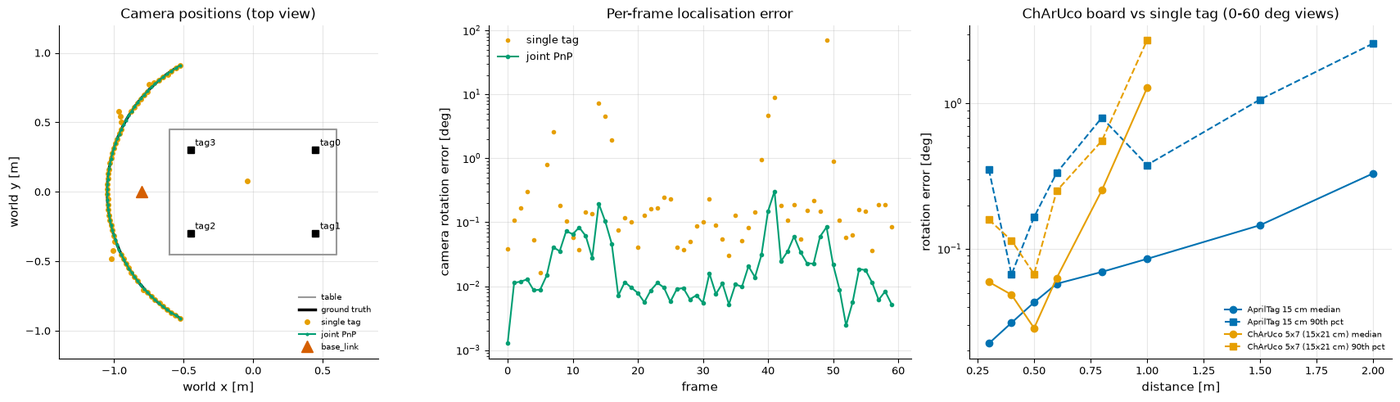

In [11]:
# --- Figure: trajectories (top view), per-frame errors, board vs tag ---
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
tw, th = scene.items[0][0].size
ax.plot([-tw / 2, tw / 2, tw / 2, -tw / 2, -tw / 2], [-th / 2, -th / 2, th / 2, th / 2, -th / 2], color="0.6", label="table")
for i, T in scene.T_world_tag.items():
    ax.plot(*T[:2, 3], "s", color="black", ms=6)
    ax.annotate(f"tag{i}", T[:2, 3], xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.plot(traj_gt[:, 0, 3], traj_gt[:, 1, 3], "-", color="black", lw=2.5, label="ground truth")
for k, (name, (_, _, _, E)) in enumerate(per_frame.items()):
    ax.plot(E[:, 0, 3], E[:, 1, 3], "o" if k == 0 else ".-", color=viz.color(k + 1, unit=True), ms=4, label=name)
ax.plot(*scene.T_world_base[:2, 3], "^", color=viz.color(5, unit=True), ms=10, label="base_link")
ax.set_xlim(-1.4, 0.9)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")
ax.set_xlabel("world x [m]")
ax.set_ylabel("world y [m]")
ax.set_title("Camera positions (top view)")
ax.legend(fontsize=7, loc="lower right")
for k, (name, (idx, _, re, _)) in enumerate(per_frame.items()):
    axes[1].semilogy(idx, np.maximum(re, 1e-3), "o-" if k else "o", color=viz.color(k + 1, unit=True), ms=3, label=name)
axes[1].set_xlabel("frame")
axes[1].set_ylabel("camera rotation error [deg]")
axes[1].set_title("Per-frame localisation error")
axes[1].legend()
for k, target in enumerate(board_summary.target.unique()):
    d = board_summary[board_summary.target == target]
    axes[2].semilogy(d.dist, d.rot_med_deg, "o-", color=viz.color(k, unit=True), label=f"{target} median")
    axes[2].semilogy(d.dist, d.rot_p90_deg, "s--", color=viz.color(k, unit=True), label=f"{target} 90th pct")
axes[2].set_xlabel("distance [m]")
axes[2].set_ylabel("rotation error [deg]")
axes[2].set_title("ChArUco board vs single tag (0-60 deg views)")
axes[2].legend(fontsize=7)
viz.savefig(fig, PROJECT, "marker_localization")
plt.show()

The head-camera view with all estimated frames and the box wireframe, also saved as the project
thumbnail.

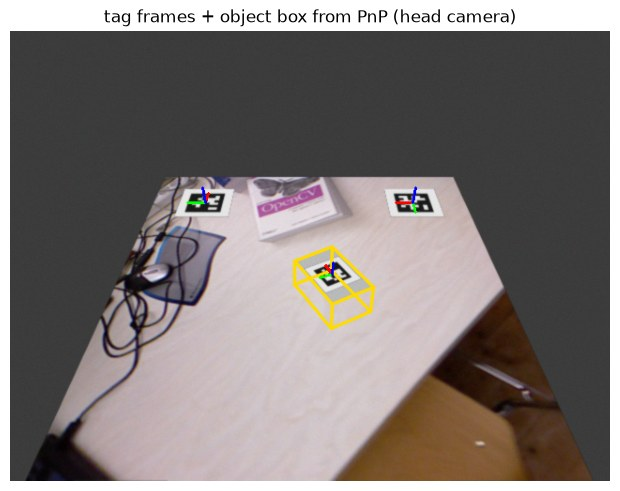

In [12]:
# --- AR overlay of the head-camera estimate (README thumbnail) ---
fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.imshow(head_vis[..., ::-1])
ax.set_title("tag frames + object box from PnP (head camera)")
ax.axis("off")
thumb = cv2.resize(head_vis[130:370, 100:580], (400, 200), interpolation=cv2.INTER_AREA)
cvio.write_image(cvio.assets_dir(PROJECT) / "thumb.png", thumb[..., ::-1])
show_jpeg(fig)

Summary table (saved to `results/frames_and_boards.json`).

In [13]:
# --- Summary table + results JSON ---
def board_at(target, dist, col):
    s = board_summary
    return float(s[(s.target == target) & (s.dist == dist)][col].iloc[0])

summary = pd.DataFrame([
    {"experiment": "object pose in base_link (head camera, 1 image)", "metric": "position / rotation error",
     "value": f"{obj_err['position_err_mm']:.1f} mm / {obj_err['rotation_err_deg']:.2f} deg"},
    *[{"experiment": f"camera localisation, {m} (60 frames)", "metric": "ATE RMSE / max rotation error",
       "value": f"{loc_df.loc[m, 'ATE_rmse_mm']:.1f} mm / {loc_df.loc[m, 'rot_err_max_deg']:.2f} deg"} for m in loc_df.index],
    *[{"experiment": f"{tg} at {dd:.1f} m", "metric": "detection rate / median rot / median trans",
       "value": f"{board_at(tg, dd, 'det_rate'):.2f} / {board_at(tg, dd, 'rot_med_deg'):.2f} deg / {board_at(tg, dd, 't_med_mm'):.1f} mm"}
      for tg in board_summary.target.unique() for dd in (0.4, 0.6, 1.0)],
])
cvio.save_json({"setup": "synthetic work cell, TUM fr1 camera 640x480, CPU",
                "object_in_base": obj_err, "grasp": grasp_df.round(5).reset_index().to_dict(orient="records"),
                "localisation": loc_df.round(4).reset_index().to_dict(orient="records"),
                "board_vs_tag": board_summary.round(4).to_dict(orient="records")},
               PROJ_DIR / "results" / "frames_and_boards.json")
summary

,experiment,metric,value
0,"object pose in base_link (head camera, 1 image)",position / rotation error,4.6 mm / 0.13 deg
1,"camera localisation, single tag (60 frames)",ATE RMSE / max rotation error,140.9 mm / 70.21 deg
2,"camera localisation, joint PnP (60 frames)",ATE RMSE / max rotation error,1.3 mm / 0.31 deg
3,AprilTag 15 cm at 0.4 m,detection rate / median rot / median trans,1.00 / 0.03 deg / 0.0 mm
4,AprilTag 15 cm at 0.6 m,detection rate / median rot / median trans,1.00 / 0.06 deg / 0.1 mm
5,AprilTag 15 cm at 1.0 m,detection rate / median rot / median trans,1.00 / 0.09 deg / 0.3 mm
6,ChArUco 5x7 (15x21 cm) at 0.4 m,detection rate / median rot / median trans,1.00 / 0.05 deg / 0.1 mm
7,ChArUco 5x7 (15x21 cm) at 0.6 m,detection rate / median rot / median trans,1.00 / 0.06 deg / 0.2 mm
8,ChArUco 5x7 (15x21 cm) at 1.0 m,detection rate / median rot / median trans,0.17 / 1.28 deg / 4.9 mm


### Takeaways

* **Let the indices chain.** Writing every transform as $T_{ab}$ and only multiplying when inner
  indices match ($T_{ab}T_{bc}$) makes chains like base <- link <- optical <- tag <- object
  mechanical; the one inverse ($T_{\text{object},\text{obj\_tag}}^{-1}$) is where most bugs hide.
* **Optical vs body frames are a fixed rotation**, not a convention you can ignore: forgetting
  `R_ROS_FROM_OPENCV` (rpy $-90°, 0, -90°$) points the camera into the table.
* **Many spread-out points beat one small square.** Joint PnP over the map tags stays at the
  millimetre level in every frame, while the single-largest-tag estimate occasionally takes the
  wrong IPPE branch and is off by tens of degrees. In a real system this is why tag *bundles*,
  boards and temporal filtering are used.
* **A board is not automatically more accurate.** With unbiased AprilTag 3 corners, the single
  15 cm tag had a lower median translation error than the 15 x 21 cm ChArUco board at every
  distance where both were detected, and a similar median rotation error (better at 0.3-0.4 m,
  worse at 0.5 m; all below 0.1 deg up to 0.6 m in this idealised render). It kept working to 2 m,
  while the board's 3 mm marker cells became unreadable beyond about 0.8 m on this 640x480
  camera. Four corners spread over 15 cm constrain the pose about as well as 24 corners on a
  3 cm grid. A board earns its place through **robustness** (partial occlusion, no single-square
  ambiguity) and as the standard target for **intrinsic calibration** (project 01), where a
  single tag gives far too few points. Real prints add effects not simulated here (paper flatness,
  printer scaling, lens distortion) that favour targets with many points.

## Exercises

Solutions: `projects/07_pose_estimation/solutions/03_frames_solutions.py`
(CPU only: `python projects/07_pose_estimation/solutions/03_frames_solutions.py`).

**Exercise 1 - rotation averaging.** Instead of one joint PnP, estimate $T_{\text{world},\text{cam}}$
from *each* visible map tag and average them: positions by the mean, rotations by the chordal $L_2$
mean (sum the rotation matrices and project back onto SO(3) with an SVD,
$\bar R = U\,\mathrm{diag}(1, 1, \det UV^\top)\,V^\top$). Compare ATE with the single-tag and joint
results. Why is a median-type robust average better here?

In [14]:
# --- Exercise 1: chordal L2 rotation averaging over per-tag camera poses ---
# TODO: for each orbit frame, compute T_world_cam from every visible map tag, average them,
# and report ATE / max rotation error next to loc_df.

**Exercise 2 - ROS frames.** Express the object pose estimated in Section 4 in the `camera_link`
frame (REP-103) and in the `camera_optical` frame, as position + quaternion $(x, y, z, w)$. Check
that converting one into the other only involves `R_ROS_FROM_OPENCV`, and write the
`camera_link -> camera_optical_frame` static transform as roll-pitch-yaw.

In [15]:
# --- Exercise 2: the object pose in camera_link vs camera_optical ---
# TODO: compute T_link_object and T_optical_object from T_base_object_est and the scene's mounting
# transforms, print both as (xyz, quaternion), and verify their relation.

**Exercise 3 - hand-eye calibration ($AX = XB$).** A camera is mounted on a robot's gripper with an
unknown offset $X = T_{\text{gripper},\text{cam}}$; a tag is fixed in the world. For several robot poses you
know $T_{\text{base},\text{gripper}}$ (kinematics) and measure $T_{\text{cam},\text{tag}}$ (PnP). For any two poses
$i, j$: $A = T_{\text{base},g_i}^{-1}T_{\text{base},g_j}$ and $B = T_{\text{cam}_i,\text{tag}}\,T_{\text{cam}_j,\text{tag}}^{-1}$ satisfy
$AX = XB$. `cv2.calibrateHandEye` is not exposed in the OpenCV 5.0.0.93 Python bindings, so implement
the Park-Martin solution: $R_X$ from the axis-angle vectors ($M = \sum_k \beta_k\alpha_k^\top$,
$R_X = (M^\top M)^{-1/2}M^\top$), then $t_X$ by least squares from $(R_A - I)\,t_X = R_X t_B - t_A$.
Simulate 10 poses with synthetic tag detections (with corner noise) and report the error of $X$.

In [16]:
# --- Exercise 3: hand-eye calibration with the Park-Martin method ---
# TODO: simulate robot poses + PnP measurements, build (A, B) pairs, solve AX = XB, compare with X_gt.